# CNN – Fruit and Vegetable Classification

## 1. Project Description

### Purpose

The purpose of this project is to build and train a Convolutional Neural Network (CNN) to classify images of nine different fruits and vegetables.

We aim to evaluate the model's classification performance and compare the results with the group's baseline model, which uses Logistic Regression.

### Method

We use the group's existing image dataset and predefined training, validation, and test splits to ensure a consistent evaluation.

The CNN learns visual features directly from the images, such as colors, shapes, and textures, rather than relying on manually extracted features.

We train the model on the training set, monitor its performance using the validation set, and evaluate its final performance on the test set using accuracy, macro-F1 score, and a confusion matrix.

## 2. Preparation

### 2.1 Import Libraries and Functions

We begin by importing the required Python libraries and shared functions from the group project.

The load_image() function is used to load and preprocess images, while evaluate_predictions() is used to evaluate model performance.

Reusing these functions helps maintain consistency across the group's models and reduces duplicated code.

In [ ]:

# Standard Python libraries
import sys                       # Access Python settings and module paths
import random
from pathlib import Path        # Work with file and folder paths

# Data analysis and visualization
import numpy as np
import pandas as pd             # Load and analyze datasets
import matplotlib.pyplot as plt # Create plots and visualize images

# PyTorch - Deep Learning
import torch                    # Main PyTorch library
import torch.nn as nn           # Neural network layers and functions
import torch.optim as optim     # Optimization algorithms
from torch.utils.data import Dataset, DataLoader  # Handle image datasets and batches

# Find the project's root directory
project_root = Path.cwd().resolve()

# Move one level up if the notebook runs from the notebooks folder
if project_root.name == "notebooks":
    project_root = project_root.parent

# Add the project directory to Python's module search path
sys.path.insert(0, str(project_root))

# Import shared functions from the group project
from src.preprocess import load_image
from src.evaluate import evaluate_predictions

# Verify the environment
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Project directory:", project_root)
print("All imports successful!")


Python version: 3.14.3
PyTorch version: 2.15.0+cpu
Project directory: C:\Users\PC\Documents\group-project
All imports successful!


## 3. CNN Implementation 

### 3.1 Load the existing train, validation and test split

We use the group's existing dataset split so that the CNN and baseline model can be evaluated on the same test images.

The CSV file contains image paths, target classes, and dataset split assignments.

Before loading the images, we inspect the dataset to verify the number of images in each split and examine the class distribution. This helps us identify potential class imbalances that could affect model performance.

In [2]:

# Load the existing dataset split
csv_path = project_root / "data" / "dataset_split.csv"
df = pd.read_csv(csv_path)

# Display the first five rows
display(df.head())

# Check the number of images in each split
print("\nImages per split:")
print(df["split"].value_counts())

# Check the available classes
print("\nClasses:")
print(sorted(df["target_class"].unique()))

# Check the total number of images
print("\nTotal images:", len(df))

# NEW: Check the class distribution within each split
# This helps identify potential class imbalances in training, validation and test data
print("\nClass distribution per split:")
print(pd.crosstab(df["target_class"], df["split"]))


,image_path,target_class,split
0,data/raw_images/fuji_apple/fuji_apple_002.jpg,apple,test
1,data/raw_images/fuji_apple/fuji_apple_023.jpg,apple,test
2,data/raw_images/fuji_apple/fuji_apple_046.jpg,apple,test
3,data/raw_images/fuji_apple/fuji_apple_053.jpg,apple,test
4,data/raw_images/fuji_apple/fuji_apple_061.jpg,apple,test



Images per split:
split
train         1603
test           200
validation     200
Name: count, dtype: int64

Classes:
['apple', 'honneydew_melon', 'kiwi', 'nectarine', 'onion', 'plum', 'potato', 'spanish_pear', 'watermelon']

Total images: 2003

Class distribution per split:
split            test  train  validation
target_class                            
apple              36    294          37
honneydew_melon    14    117          14
kiwi               15    140          16
nectarine          25    198          24
onion               8     60           7
plum               27    211          26
potato             39    305          39
spanish_pear       16    126          17
watermelon         20    152          20


### 3.2 Load and preprocess images

We use the group's existing `load_image()` function to load and preprocess the images.

Before preparing the dataset for CNN training, we visualize six randomly selected training images to verify that they are loaded correctly and match their assigned labels.

We also inspect the dimensions and pixel value range of one loaded image to check its format.

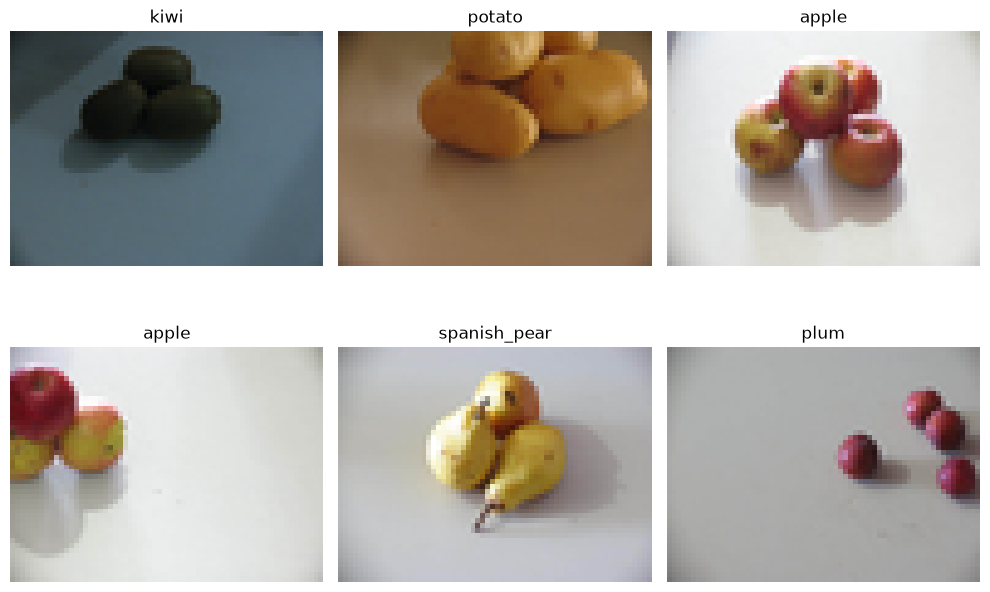

Image shape: (48, 64, 3)
Pixel range: 0.0627451 to 0.8666667


In [3]:

# Select six images from the training dataset
train_df = df[df["split"] == "train"]
sample = train_df.sample(n=6, random_state=42)

# Display the images in a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = project_root / row["image_path"]
    image = load_image(image_path)

    ax.imshow(image)
    ax.set_title(row["target_class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Check image dimensions and pixel values
print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())


#### 3.2.1 Label encoding

We convert the fruit and vegetable class names into numerical labels (0–8), as PyTorch's classification loss function requires integer class labels.

The same class mapping is used for the training, validation, and test datasets to ensure consistent label encoding.

In [4]:

# Get the unique class names from the training dataset and sort them alphabetically
class_names = sorted(train_df["target_class"].unique())

# Create a dictionary that maps each class name to a numerical label
# enumerate() assigns an index starting from 0 to each class name
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# Display the number of classes and their numerical labels
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_idx)


Number of classes: 9
Class mapping: {'apple': 0, 'honneydew_melon': 1, 'kiwi': 2, 'nectarine': 3, 'onion': 4, 'plum': 5, 'potato': 6, 'spanish_pear': 7, 'watermelon': 8}


#### 3.2.2 Create a PyTorch Dataset

We create a custom PyTorch Dataset using the group's existing `load_image()` function.

Each image is loaded and converted into a PyTorch tensor with the required dimensions (channels, height, width). The image is then paired with its corresponding numerical class label.

The Dataset class allows images and labels to be accessed individually during training and evaluation.

In [5]:

# Create a custom PyTorch Dataset class
class FruitDataset(Dataset):

    # Initialize the dataset with image information and class mapping
    def __init__(self, dataframe, project_root, class_to_idx):
        self.dataframe = dataframe.reset_index(drop=True)
        self.project_root = project_root
        self.class_to_idx = class_to_idx

    # Return the total number of images in the dataset
    def __len__(self):
        return len(self.dataframe)

    # Load and return one image and its corresponding label
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Load the image using the group's existing function
        image_path = self.project_root / row["image_path"]
        image = load_image(image_path)

        # Convert the NumPy image into a PyTorch tensor
        # Change dimensions from (height, width, channels)
        # to (channels, height, width)
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Convert the class name into its numerical label
        label = self.class_to_idx[row["target_class"]]

        # Convert the label into a tensor of integer type
        label = torch.tensor(label, dtype=torch.long)

        # Return the image tensor and its label
        return image, label


#### 3.2.3 Create DataLoaders

We create training and validation datasets using our custom `FruitDataset` class.

PyTorch DataLoaders divide the images into batches of 32, allowing the model to process multiple images at a time.

The training data is shuffled to vary the order of images between epochs, while the validation data is kept in a fixed order for consistent evaluation.

The test dataset is reserved for the final model evaluation.

In [6]:

# Select validation images using the group's existing dataset split
val_df = df[df["split"] == "validation"]

# Create training and validation datasets
train_dataset = FruitDataset(train_df, project_root, class_to_idx)
val_dataset = FruitDataset(val_df, project_root, class_to_idx)

# Create DataLoaders that process 32 images per batch
# Shuffle training data to vary the order between epochs
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Keep validation data in a fixed order
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Display the number of images in each dataset
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 1603
Validation images: 200


### 3.3 Build the CNN model

We build a Convolutional Neural Network (CNN) using PyTorch to classify images into nine fruit and vegetable classes.

The model consists of two convolutional layers that extract visual features from the images. Each convolutional layer is followed by a ReLU activation function and max pooling, which reduces the spatial dimensions of the feature maps.

The extracted features are flattened and passed through fully connected layers to produce a prediction score for each class.

The model outputs nine scores (logits), which are used during training to calculate the classification loss.

We also set a fixed random seed before initializing the CNN to make our training results more reproducible and allow fairer comparisons between different model settings.

In [ ]:
# Set a fixed random seed for reproducibility
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Set the seed for CUDA GPUs if available
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

print("Random seed:", seed)

Random seed: 42


In [13]:

# Define a Convolutional Neural Network for image classification
class FruitCNN(nn.Module):

    # Initialize the model with the number of output classes
    def __init__(self, num_classes=9):
        super().__init__()

        # Extract visual features from the input images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 3 input channels, 16 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2),                            # Reduce height and width by half

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 input channels, 32 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2)                             # Reduce height and width by half
        )

        # Classify the extracted image features
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # Convert feature maps into a one-dimensional vector
            nn.Linear(32 * 12 * 16, 128), # Connect extracted features to 128 neurons
            nn.ReLU(),                     # Introduce non-linearity
            nn.Linear(128, num_classes)    # Output one score for each class
        )

    # Define how data moves through the network
    def forward(self, x):
        x = self.features(x)      # Extract visual features
        x = self.classifier(x)    # Calculate class scores
        return x                 # Return the logits

# Create the CNN model using the number of available classes
model = FruitCNN(num_classes=len(class_names))

# Display the model architecture
print(model)


FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)


#### 3.3.1 Verify Model Input and Output Dimensions

Before training, we verify that the CNN accepts batches of preprocessed images and produces one prediction score per class. This helps detect potential dimension mismatches.

In [8]:
# Get one batch of images and labels
images, labels = next(iter(train_loader))

# Display the batch dimensions and data type
print("Batch shape:", images.shape)
print("Image dtype:", images.dtype)

# Pass the batch through the CNN without calculating gradients
with torch.no_grad():
    outputs = model(images)

# Check that the model produces one score per class
print("Output shape:", outputs.shape)

Batch shape: torch.Size([32, 3, 48, 64])
Image dtype: torch.float32
Output shape: torch.Size([32, 9])


### 3.4 Configure model training

We use CrossEntropyLoss to measure the difference between the model's predicted class scores and the correct class labels.

The Adam optimizer updates the model's weights during training to minimize the loss. We use a learning rate of 0.001, which controls the size of the optimization steps.

The model automatically selects an available GPU (CUDA for NVIDIA or MPS for Apple Silicon). If GPU acceleration is unavailable, training runs on the CPU.

In [14]:
# Select the best available device for training
if torch.cuda.is_available():
    device = torch.device("cuda")  # NVIDIA GPU, commonly used on Windows

elif torch.backends.mps.is_available():
    device = torch.device("mps")   # Apple Silicon GPU (Mac)

else:
    device = torch.device("cpu")   # Fallback for computers without supported GPU acceleration

# Move the CNN model to the selected device
model = model.to(device)

# Define the loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Define the Adam optimizer with a learning rate of 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Display the training configuration
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam


### 3.5 Train the CNN model

We train the CNN for 10 epochs using the training dataset. During each epoch, the model updates its weights using the Adam optimizer to minimize the classification loss.

After each epoch, we evaluate the model on the validation dataset without updating its weights.

We record training and validation loss and accuracy to monitor the model's learning progress and identify potential overfitting.

We also save the model with the lowest validation loss to make sure we keep the best-performing model during training.

In [15]:
# Define the number of training epochs
num_epochs = 10

# Create lists to store training and validation metrics
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Track the best validation loss and corresponding epoch
best_val_loss = float("inf")
best_epoch = 0

# Define where to save the best model
best_model_path = project_root / "best_cnn_model.pth"

# Repeat training and validation for each epoch
for epoch in range(num_epochs):

    # --- TRAINING ---
    model.train()  # Set the model to training mode
    running_loss = 0
    correct = 0
    total = 0

    # Process one batch of training images at a time
    for images, labels in train_loader:
        images = images.to(device)  # Move images to GPU or CPU
        labels = labels.to(device)  # Move labels to the same device

        optimizer.zero_grad()  # Clear gradients from the previous batch

        outputs = model(images)  # Calculate prediction scores
        loss = criterion(outputs, labels)  # Calculate classification loss

        loss.backward()  # Calculate gradients
        optimizer.step()  # Update model weights

        # Accumulate loss, weighted by the number of images in the batch
        running_loss += loss.item() * images.size(0)

        # Count correct predictions
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Calculate average training loss and accuracy
    train_loss = running_loss / total
    train_accuracy = correct / total

    # --- VALIDATION ---
    model.eval()  # Set the model to evaluation mode
    running_val_loss = 0
    val_correct = 0
    val_total = 0

    # Disable gradient calculations during validation
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            # Accumulate validation loss
            running_val_loss += loss.item() * images.size(0)

            # Count correct validation predictions
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # Calculate average validation loss and accuracy
    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # Save metrics for visualization
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Save the model if validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_model_path)

    # Display results after each epoch
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

# Display the best model results
print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model saved to: {best_model_path}")

Epoch 1/10 | Train loss: 1.6284 | Val loss: 1.1877 | Train accuracy: 40.36% | Val accuracy: 62.00%
Epoch 2/10 | Train loss: 0.7976 | Val loss: 0.5808 | Train accuracy: 72.24% | Val accuracy: 79.50%
Epoch 3/10 | Train loss: 0.4683 | Val loss: 0.4659 | Train accuracy: 83.97% | Val accuracy: 82.50%
Epoch 4/10 | Train loss: 0.3426 | Val loss: 0.3637 | Train accuracy: 87.71% | Val accuracy: 87.50%
Epoch 5/10 | Train loss: 0.2940 | Val loss: 0.3948 | Train accuracy: 89.46% | Val accuracy: 84.00%
Epoch 6/10 | Train loss: 0.1999 | Val loss: 0.2838 | Train accuracy: 93.51% | Val accuracy: 90.50%
Epoch 7/10 | Train loss: 0.1828 | Val loss: 0.2121 | Train accuracy: 94.45% | Val accuracy: 93.50%
Epoch 8/10 | Train loss: 0.1238 | Val loss: 0.2288 | Train accuracy: 96.38% | Val accuracy: 90.50%
Epoch 9/10 | Train loss: 0.1109 | Val loss: 0.2695 | Train accuracy: 96.57% | Val accuracy: 87.50%
Epoch 10/10 | Train loss: 0.1618 | Val loss: 0.1536 | Train accuracy: 95.63% | Val accuracy: 94.00%

Best epo

### 3.6 Visualize training results

We visualize training and validation loss and accuracy across the 10 epochs.

These plots help us monitor the CNN's learning progress and identify potential signs of overfitting.

By comparing training and validation performance, we can assess how well the model generalizes to unseen validation images.

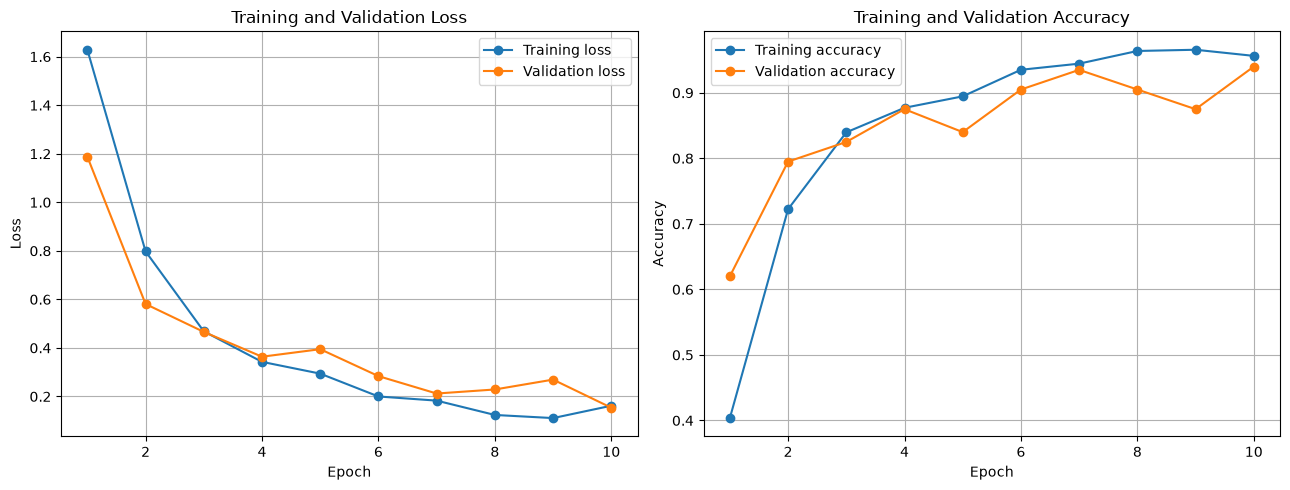

In [16]:

# Create epoch numbers for the x-axis
epochs = range(1, num_epochs + 1)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot training and validation loss
axes[0].plot(epochs, train_losses, label="Training loss", marker="o")
axes[0].plot(epochs, val_losses, label="Validation loss", marker="o")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation accuracy
axes[1].plot(epochs, train_accuracies, label="Training accuracy", marker="o")
axes[1].plot(epochs, val_accuracies, label="Validation accuracy", marker="o")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# Adjust layout and display the plots
plt.tight_layout()
plt.show()


#### 3.6.1 Analysis of training results

Both training and validation loss decrease overall, showing that the CNN is learning to recognize the different fruit classes.

Training accuracy increases from 40.36% to 95.63%, while validation accuracy improves from 62% to 94%.

The validation curves fluctuate slightly during the later epochs, but there are no clear signs of serious overfitting.

The lowest validation loss (0.1536) is reached at epoch 10, and this model is saved for further evaluation.

Overall, the results show that the CNN performs well on the validation dataset.

### 3.7 Evaluate the CNN on validation data

We evaluate the best saved CNN model using the validation dataset.

We compare the predicted labels with the actual labels to identify which fruit and vegetable classes the model recognizes correctly and which classes it confuses.

The test dataset is reserved for final evaluation.

In [17]:
# Load the best model saved during training
best_model = FruitCNN(num_classes=len(class_names)).to(device)
best_model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

# Set the model to evaluation mode
best_model.eval()

# Create lists to store actual and predicted labels
y_true = []
y_pred = []

# Evaluate the model without updating its weights
with torch.no_grad():
    for images, labels in val_loader:

        # Move images to the selected device
        images = images.to(device)

        # Predict the fruit and vegetable classes
        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        # Collect actual labels and predictions
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Display the number of evaluated images and correct predictions
correct_predictions = sum(
    actual == predicted for actual, predicted in zip(y_true, y_pred)
)

print("Validation images evaluated:", len(y_true))
print("Correct predictions:", correct_predictions)
print(f"Validation accuracy: {correct_predictions / len(y_true):.2%}")

Validation images evaluated: 200
Correct predictions: 188
Validation accuracy: 94.00%


#### 3.7.1 Confusion Matrix

We use a confusion matrix to visualize how well the CNN classifies each fruit and vegetable class.

The diagonal shows correct predictions, while values outside the diagonal show which classes the model confuses.

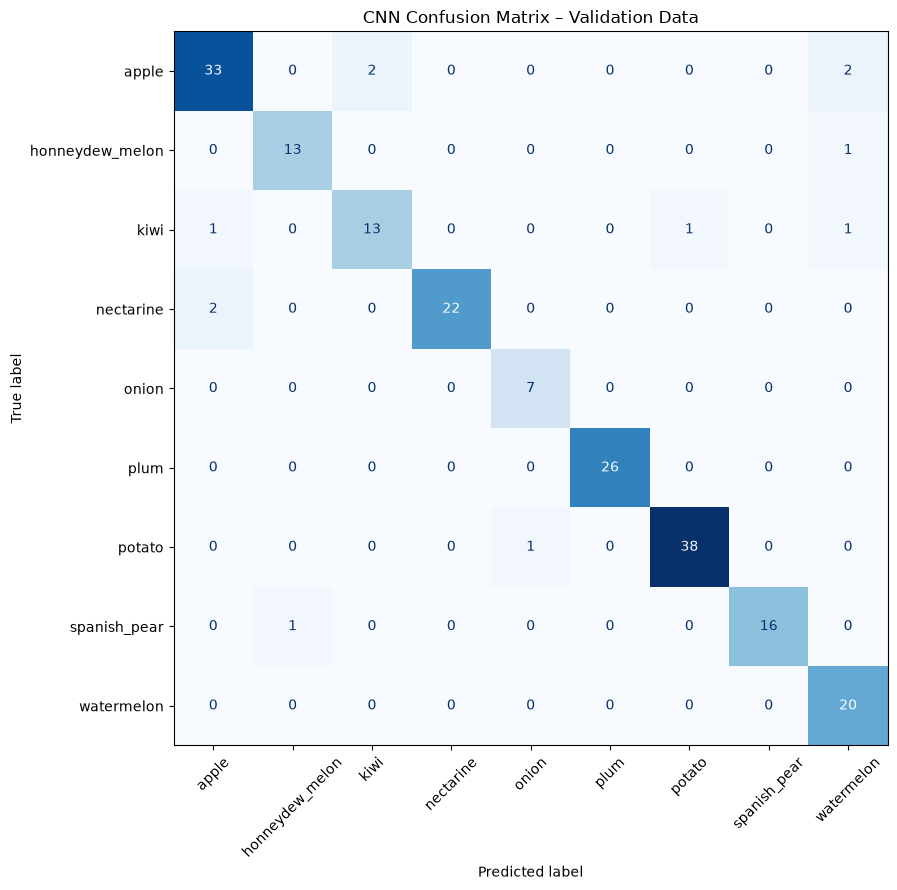

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix using actual and predicted labels
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Visualize the confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN Confusion Matrix – Validation Data")

plt.tight_layout()
plt.show()

#### 3.7.2 Classification Report

We use a classification report to evaluate precision, recall and F1-score for each class.

This gives us a more detailed understanding of the CNN's performance, especially since the number of images differs between classes.

In [19]:
from sklearn.metrics import classification_report

# Generate classification metrics for all fruit and vegetable classes
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
)

# Display precision, recall, F1-score and support
print(report)

                 precision    recall  f1-score   support

          apple       0.92      0.89      0.90        37
honneydew_melon       0.93      0.93      0.93        14
           kiwi       0.87      0.81      0.84        16
      nectarine       1.00      0.92      0.96        24
          onion       0.88      1.00      0.93         7
           plum       1.00      1.00      1.00        26
         potato       0.97      0.97      0.97        39
   spanish_pear       1.00      0.94      0.97        17
     watermelon       0.83      1.00      0.91        20

       accuracy                           0.94       200
      macro avg       0.93      0.94      0.93       200
   weighted avg       0.94      0.94      0.94       200



#### 3.7.3 Analysis of validation results

The CNN correctly classifies 188 out of 200 validation images, achieving an accuracy of 94%.

The classification report shows a macro F1-score of 0.93, indicating good performance across the nine classes.

The confusion matrix shows that plum and watermelon are correctly classified in all cases. Kiwi has the lowest F1-score (0.84), making it the most challenging class for the model.

Some apples are confused with kiwi and watermelon, while two nectarines are classified as apples.

Overall, the CNN performs well on the validation dataset, but there is still room for improvement in distinguishing certain classes.